<a href="https://colab.research.google.com/github/jonathanxuningzhu/Deeplearning/blob/main/Binary%20Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import make_circles

n_samples = 1000

X,y = make_circles(n_samples,noise = 0.03,random_state = 42)

print(f"First five features {X[:5]}")
print(f"First five labels{y[:5]}")

First five features [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First five labels[1 1 1 1 0]


In [ ]:
import pandas as pd
circles = pd.DataFrame({
    "X1": X[:, 0],
    "X2": X[:, 1],
    "label": y
})

circles.head(10)

circles.label.value_counts()

,count
label,
1,500
0,500


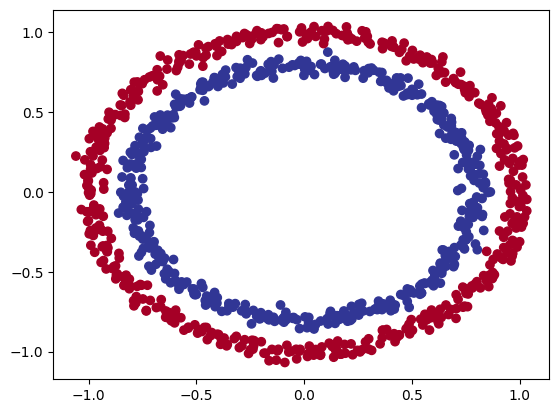

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(x=X[:,0],y=X[:,1],c=y,cmap=plt.cm.RdYlBu);

In [ ]:
X.shape,y.shape

X_sample = X[0]

y_sample = y[0]

print(f"The Value of one sample in X is {X_sample} and the same for y is {y_sample}")



The Value of one sample in X is [0.75424625 0.23148074] and the same for y is 1


In [ ]:
import torch

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)


X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

len(X_train),len(X_test),len(y_train),len(y_test)


(800, 200, 800, 200)

In [ ]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cuda'

In [ ]:
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2,out_features=10)
    self.layer_2 = nn.Linear(in_features=10,out_features=10)
    self.layer_3 = nn.Linear(in_features=10,out_features=1)

  def forward(self,x):
    return self.layer_3(self.layer_2(self.layer_1(x)))
model_0 = CircleModelV0().to(device)

untrained_preds = model_0(X_test.to(device))

print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(params=model_0.parameters(),lr = 0.1)

def accuracy_fn(y_true,y_pred):
  correct = torch.eq(y_true,y_pred).sum().item()
  acc = (correct/len(y_pred))*100
  return acc

y_logits = model_0(X_test.to(device))[:5]



y_pred_probs = torch.sigmoid(y_logits)

y_preds = torch.round(y_pred_probs)

y_pred_labels = y_preds

y_test[:5]


torch.manual_seed(42)

epochs = 1000

X_train, y_train = X_train.to(device), y_train.to(device)

X_test,y_test = X_test.to(device),y_test.to(device)

for epoch in range(epochs):
  model_0.train()

  y_logits = model_0(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  loss = loss_fn(y_logits,y_train)

  acc = accuracy_fn(y_true = y_train,y_pred = y_pred)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_0.eval()

  with torch.inference_mode():

    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits,y_test)

    test_acc = accuracy = accuracy_fn(y_true=y_test,y_pred=test_pred)

  print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}")





Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[0.1572],
        [0.1222],
        [0.2737],
        [0.1241],
        [0.3129],
        [0.2912],
        [0.1616],
        [0.2012],
        [0.2719],
        [0.1203]], device='cuda:0', grad_fn=<SliceBackward0>)

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])
Epoch: 0 | Loss: 0.70124, Accuracy: 50.0 | Test loss: 0.69679, Test acc: 50.00
Epoch: 1 | Loss: 0.70034, Accuracy: 50.0 | Test loss: 0.69609, Test acc: 50.00
Epoch: 2 | Loss: 0.69956, Accuracy: 50.0 | Test loss: 0.69547, Test acc: 50.00
Epoch: 3 | Loss: 0.69887, Accuracy: 50.0 | Test loss: 0.69494, Test acc: 50.00
Epoch: 4 | Loss: 0.69827, Accuracy: 50.0 | Test loss: 0.69448, Test acc: 50.00
Epoch: 5 | Loss: 0.69774, Accuracy: 50.0 | Test loss: 0.69408, Test acc: 50.00
Epoch: 6 | Loss: 0.69728, Accuracy: 50.0 | Test loss: 0.69373, Test acc: 50.00
Epoch: 7 | Loss: 0

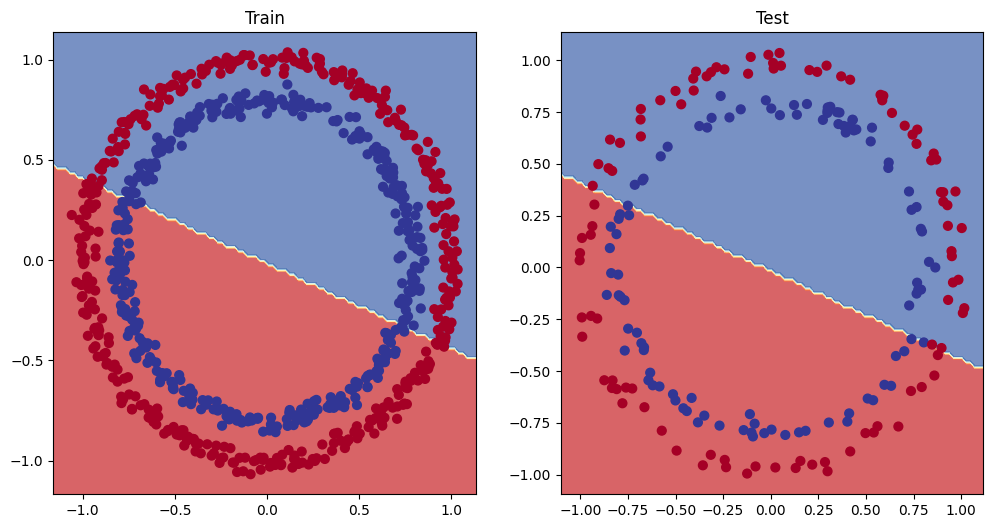

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

100


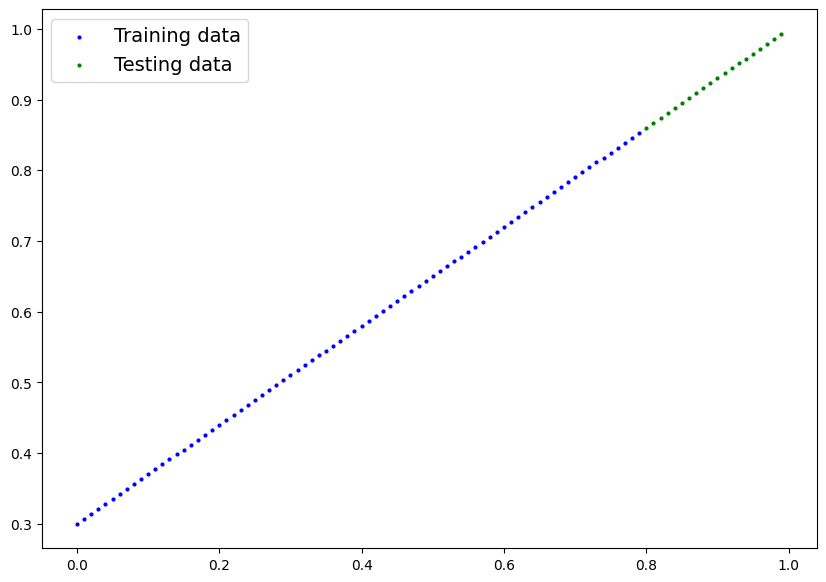

In [ ]:

weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.01


X_regression = torch.arange(start, end, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias


print(len(X_regression))
X_regression[:5], y_regression[:5]

train_split = int(0.8 * len(X_regression))

X_train_regression = X_regression[:train_split]
y_train_regression = y_regression[:train_split]

X_test_regression = X_regression[train_split:]
y_test_regression = y_regression[train_split:]

plot_predictions(train_data=X_train_regression,
    train_labels=y_train_regression,
    test_data=X_test_regression,
    test_labels=y_test_regression
)

Epoch: 0 | Train loss: 0.75986 | Test loss: 0.54143
Epoch: 100 | Train loss: 0.09309 | Test loss: 0.02901
Epoch: 200 | Train loss: 0.07376 | Test loss: 0.02850
Epoch: 300 | Train loss: 0.06745 | Test loss: 0.00615
Epoch: 400 | Train loss: 0.06107 | Test loss: 0.02004
Epoch: 500 | Train loss: 0.05698 | Test loss: 0.01061
Epoch: 600 | Train loss: 0.04857 | Test loss: 0.01326
Epoch: 700 | Train loss: 0.06109 | Test loss: 0.02127
Epoch: 800 | Train loss: 0.05599 | Test loss: 0.01426
Epoch: 900 | Train loss: 0.05571 | Test loss: 0.00603


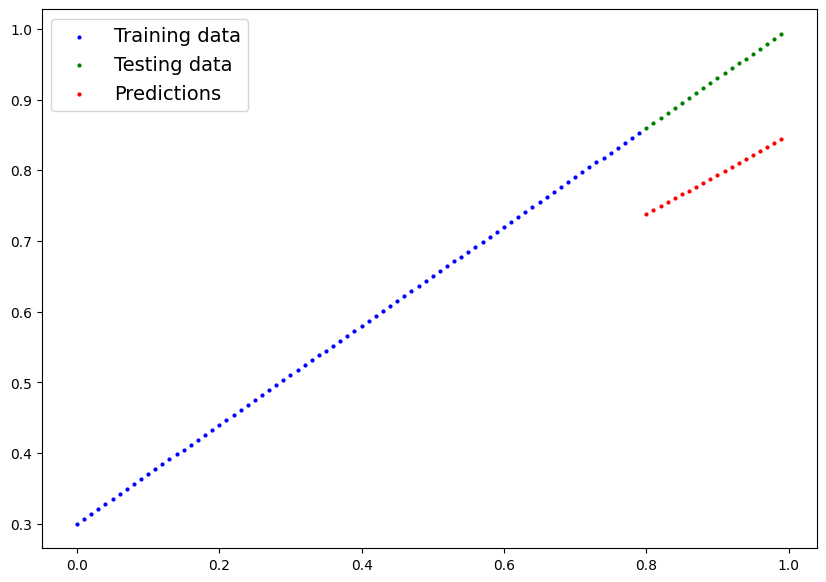

In [ ]:

torch.manual_seed(42)

model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)


loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(model_2.parameters(), lr=0.1)

epochs = 1000


X_train_regression = X_train_regression.to(device)
y_train_regression = y_train_regression.to(device)
X_test_regression = X_test_regression.to(device)
y_test_regression = y_test_regression.to(device)

for epoch in range(epochs):

    model_2.train()

    y_pred = model_2(X_train_regression)
    loss = loss_fn(y_pred, y_train_regression)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    model_2.eval()
    with torch.inference_mode():
        test_pred = model_2(X_test_regression)
        test_loss = loss_fn(test_pred, y_test_regression)


    if epoch % 100 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.5f} | "
            f"Test loss: {test_loss.item():.5f}"
        )


model_2.eval()


with torch.inference_mode():
    y_preds = model_2(X_test_regression)


plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_preds.cpu());

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)
Epoch: 0 | Loss: 0.69541, Accuracy: 50.00% | Test Loss: 0.69584, Test Accuracy: 50.00%
Epoch: 1 | Loss: 0.69516, Accuracy: 50.00% | Test Loss: 0.69558, Test Accuracy: 50.00%
Epoch: 2 | Loss: 0.69490, Accuracy: 50.00% | Test Loss: 0.69532, Test Accuracy: 50.00%
Epoch: 3 | Loss: 0.69464, Accuracy: 50.00% | Test Loss: 0.69507, Test Accuracy: 50.00%
Epoch: 4 | Loss: 0.69439, Accuracy: 50.00% | Test Loss: 0.69484, Test Accuracy: 50.00%
Epoch: 5 | Loss: 0.69415, Accuracy: 50.00% | Test Loss: 0.69464, Test Accuracy: 50.00%
Epoch: 6 | Loss: 0.69394, Accuracy: 50.00% | Test Loss: 0.69446, Test Accuracy: 50.00%
Epoch: 7 | Loss: 0.69374, Accuracy: 50.00% | Test Loss: 0.69430, Test Accuracy: 50.00%
Epoch: 8 | Loss: 0.69356, Accuracy: 50.00% | Test Loss: 0.69416, Test Accuracy: 

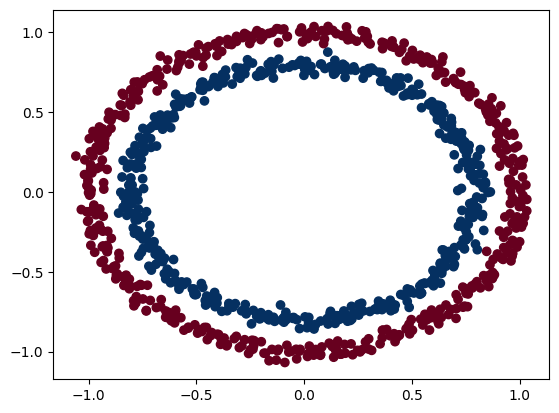

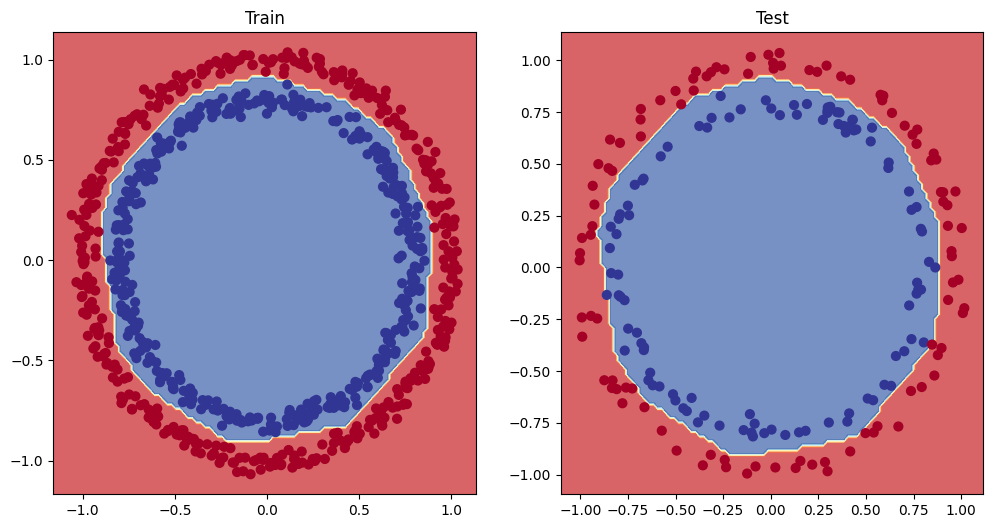

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples=1000,
    noise=0.03,
    random_state=42,
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu);




X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42
)

X_train[:5], y_train[:5]


class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):

       return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_3 = CircleModelV2().to(device)
print(model_3)


loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.1)



torch.manual_seed(42)
epochs = 3200


X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):

    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))


    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)


    optimizer.zero_grad()


    loss.backward()


    optimizer.step()


    model_3.eval()
    with torch.inference_mode():

      test_logits = model_3(X_test).squeeze()
      test_pred = torch.round(torch.sigmoid(test_logits))
      test_loss = loss_fn(test_logits, y_test)
      test_acc = accuracy_fn(y_true=y_test,
                             y_pred=test_pred)


    #if epoch % 100 == 0:
      print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")


model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10], y[:10]



plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)